In [1]:
import pandas as pd
merged_csv = pd.read_csv(r"rd/India_Lantana_Complete_Model_Inputs.csv")


In [2]:
rename_dict = {
    "wc2.1_10m_bio_1": "bio1_annual_mean_temperature",
    "wc2.1_10m_bio_2": "bio2_mean_diurnal_range",
    "wc2.1_10m_bio_3": "bio3_isothermality",
    "wc2.1_10m_bio_4": "bio4_temperature_seasonality",
    "wc2.1_10m_bio_5": "bio5_max_temp_warmest_month",
    "wc2.1_10m_bio_6": "bio6_min_temp_coldest_month",
    "wc2.1_10m_bio_7": "bio7_temperature_annual_range",
    "wc2.1_10m_bio_8": "bio8_mean_temp_wettest_quarter",
    "wc2.1_10m_bio_9": "bio9_mean_temp_driest_quarter",
    "wc2.1_10m_bio_10": "bio10_mean_temp_warmest_quarter",
    "wc2.1_10m_bio_11": "bio11_mean_temp_coldest_quarter",
    "wc2.1_10m_bio_12": "bio12_annual_precipitation",
    "wc2.1_10m_bio_13": "bio13_precipitation_wettest_month",
    "wc2.1_10m_bio_14": "bio14_precipitation_driest_month",
    "wc2.1_10m_bio_15": "bio15_precipitation_seasonality",
    "wc2.1_10m_bio_16": "bio16_precipitation_wettest_quarter",
    "wc2.1_10m_bio_17": "bio17_precipitation_driest_quarter",
    "wc2.1_10m_bio_18": "bio18_precipitation_warmest_quarter",
    "wc2.1_10m_bio_19": "bio19_precipitation_coldest_quarter"
}

# Apply renaming
merged_csv = merged_csv.rename(columns=rename_dict)
merged_csv.to_csv("India_Lantana_Complete_Model_Inputs.csv", index=False)
print(merged_csv.columns.tolist())

['gbifID', 'datasetKey', 'occurrenceID', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species_x', 'infraspecificEpithet', 'taxonRank', 'scientificName', 'verbatimScientificName', 'verbatimScientificNameAuthorship', 'countryCode_x', 'locality', 'stateProvince', 'occurrenceStatus', 'individualCount', 'publishingOrgKey', 'decimalLatitude', 'decimalLongitude', 'coordinateUncertaintyInMeters', 'coordinatePrecision', 'elevation', 'elevationAccuracy', 'depth', 'depthAccuracy', 'eventDate', 'day', 'month', 'year', 'taxonKey', 'speciesKey', 'basisOfRecord', 'institutionCode', 'collectionCode', 'catalogNumber', 'recordNumber', 'identifiedBy', 'dateIdentified', 'license', 'rightsHolder', 'recordedBy', 'typeStatus', 'establishmentMeans', 'lastInterpreted', 'mediaType', 'issue', 'geometry', 'index_right', 'ID', 'TRK_NME', 'FTR_CRY', 'CITY_NME', 'STT_NME', 'SHAPE_Leng', 'dist_in_km_railways', 'dist_in_km_road', 'dist_in_km_river', 'distance_in_km_urban', 'distance_in_km_lakes', 'specie

In [3]:

selected_cols = list(rename_dict.values()) + ['dist_in_km_railways',
       'dist_in_km_road', 'dist_in_km_river', 'distance_in_km_urban',
       'distance_in_km_lakes'] 

corr_matrix = merged_csv[selected_cols].corr()

print(corr_matrix)


                                     bio1_annual_mean_temperature  \
bio1_annual_mean_temperature                             1.000000   
bio2_mean_diurnal_range                                 -0.090982   
bio3_isothermality                                       0.183966   
bio4_temperature_seasonality                            -0.166254   
bio5_max_temp_warmest_month                              0.559371   
bio6_min_temp_coldest_month                              0.636765   
bio7_temperature_annual_range                           -0.130569   
bio8_mean_temp_wettest_quarter                           0.711173   
bio9_mean_temp_driest_quarter                            0.754472   
bio10_mean_temp_warmest_quarter                          0.786527   
bio11_mean_temp_coldest_quarter                          0.760771   
bio12_annual_precipitation                              -0.025437   
bio13_precipitation_wettest_month                       -0.030088   
bio14_precipitation_driest_month  

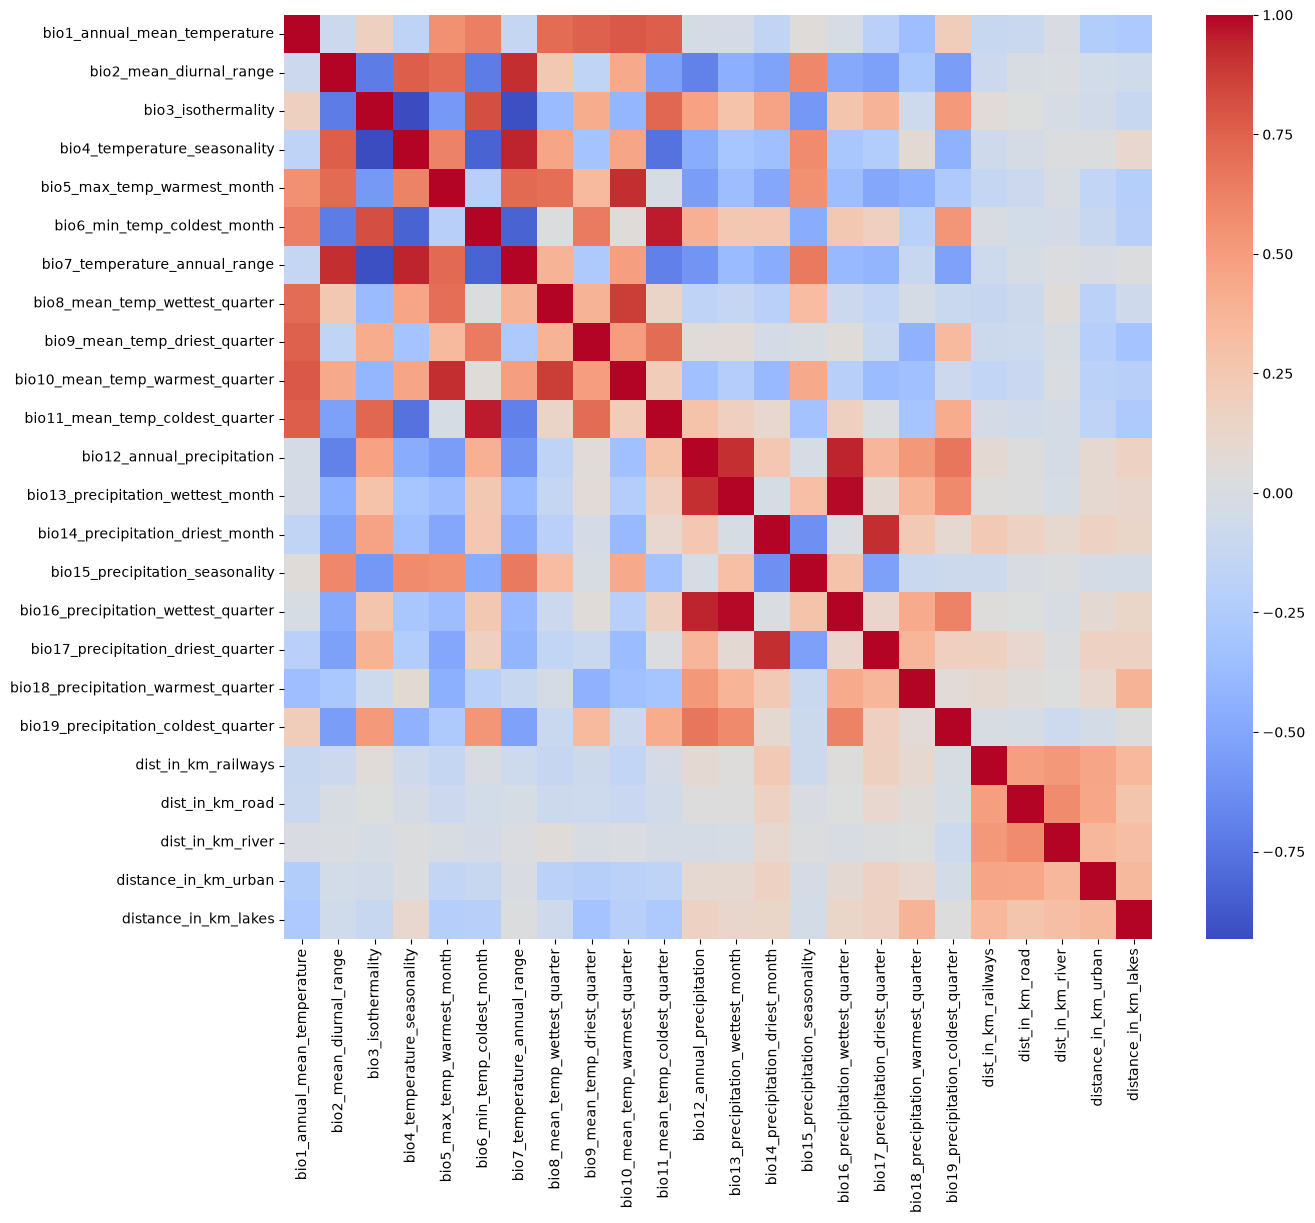

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14,12))
sns.heatmap(corr_matrix, cmap="coolwarm", annot=False)
plt.show()


In [5]:
strong_corr = corr_matrix[(corr_matrix.abs() > 0.7) & (corr_matrix.abs() < 1.0)]

                                     bio1_annual_mean_temperature  \
bio1_annual_mean_temperature                                  NaN   
bio2_mean_diurnal_range                                       NaN   
bio3_isothermality                                            NaN   
bio4_temperature_seasonality                                  NaN   
bio5_max_temp_warmest_month                                   NaN   
bio6_min_temp_coldest_month                                   NaN   
bio7_temperature_annual_range                                 NaN   
bio8_mean_temp_wettest_quarter                           0.711173   
bio9_mean_temp_driest_quarter                            0.754472   
bio10_mean_temp_warmest_quarter                          0.786527   
bio11_mean_temp_coldest_quarter                          0.760771   
bio12_annual_precipitation                                    NaN   
bio13_precipitation_wettest_month                             NaN   
bio14_precipitation_driest_month  

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [7]:
X = merged_csv[selected_cols]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [8]:
# Run PCA
pca = PCA(n_components=len(selected_cols))  # keep all components initially
X_pca = pca.fit_transform(X_scaled)

# Explained variance ratio
print("Explained variance ratio:", pca.explained_variance_ratio_)


Explained variance ratio: [3.27688940e-01 2.04873435e-01 1.26853728e-01 1.03767081e-01
 6.81439111e-02 3.37954970e-02 2.72330360e-02 2.42754961e-02
 2.08668332e-02 1.66429816e-02 1.55900635e-02 1.11936831e-02
 7.76659152e-03 4.20732454e-03 2.64551250e-03 2.19807528e-03
 9.56852519e-04 7.13210213e-04 2.86325301e-04 1.45743190e-04
 7.14657854e-05 7.06658752e-05 1.35473107e-05 5.09480082e-16]


In [9]:
import numpy as np

cum_var = np.cumsum(pca.explained_variance_ratio_)
print("Cumulative variance:", cum_var)


Cumulative variance: [0.32768894 0.53256238 0.6594161  0.76318318 0.8313271  0.86512259
 0.89235563 0.91663112 0.93749796 0.95414094 0.969731   0.98092469
 0.98869128 0.9928986  0.99554411 0.99774219 0.99869904 0.99941225
 0.99969858 0.99984432 0.99991579 0.99998645 1.         1.        ]


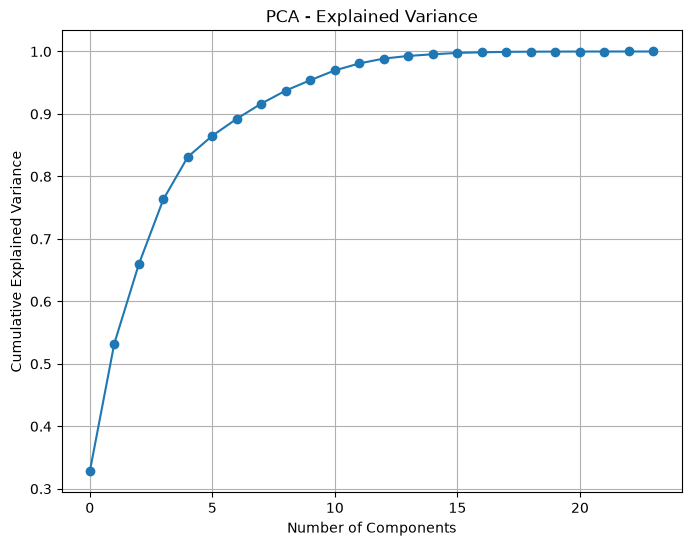

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Explained Variance')
plt.grid(True)
plt.show()


In [11]:
loadings = pd.DataFrame(pca.components_.T,
                        columns=[f'PC{i+1}' for i in range(len(selected_cols))],
                        index=selected_cols)

                                          PC1       PC2       PC3       PC4  \
bio1_annual_mean_temperature        -0.007142  0.415584  0.042105  0.178405   
bio2_mean_diurnal_range              0.328528 -0.013933  0.000726  0.000480   
bio3_isothermality                  -0.314694  0.112799 -0.129008 -0.008156   
bio4_temperature_seasonality         0.314829 -0.100890  0.124964  0.034868   
bio5_max_temp_warmest_month          0.274412  0.246887  0.063852  0.126290   
bio6_min_temp_coldest_month         -0.263902  0.285833 -0.064672  0.072596   
bio7_temperature_annual_range        0.344113 -0.061019  0.082383  0.020927   
bio8_mean_temp_wettest_quarter       0.150100  0.247784  0.144414  0.189496   
bio9_mean_temp_driest_quarter       -0.070628  0.374765  0.008053  0.123623   
bio10_mean_temp_warmest_quarter      0.197253  0.319348  0.107632  0.172600   
bio11_mean_temp_coldest_quarter     -0.207682  0.342484 -0.050673  0.090055   
bio12_annual_precipitation          -0.265045 -0.047

In [12]:
from sklearn.decomposition import PCA

pca = PCA(n_components=6)
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame of scores
pca_df = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(6)])
print(pca_df.head())


         PC1        PC2       PC3        PC4        PC5       PC6
0 -12.632126 -25.151937 -2.697094  75.987402 -12.800413  0.030697
1  -3.463753  -2.360395  2.648556  -0.980532  -2.227986 -0.768824
2  -2.987808  -2.567758  1.944774   0.247304  -2.513263 -0.390719
3  -4.181008   1.626925  3.575817   0.347715  -1.088598 -1.084891
4  -2.993102  -2.593133  1.944356   0.336142  -2.549595 -0.427151


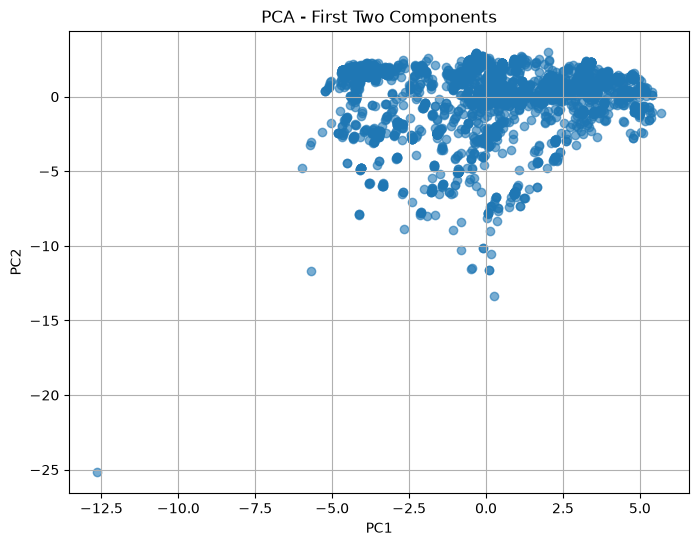

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(pca_df["PC1"], pca_df["PC2"], alpha=0.6)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - First Two Components")
plt.grid(True)
plt.show()


In [14]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(6)],
    index=selected_cols
)

                                          PC1       PC2       PC3       PC4  \
bio1_annual_mean_temperature        -0.007142  0.415584  0.042105  0.178405   
bio2_mean_diurnal_range              0.328528 -0.013933  0.000726  0.000480   
bio3_isothermality                  -0.314694  0.112799 -0.129008 -0.008156   
bio4_temperature_seasonality         0.314829 -0.100890  0.124964  0.034868   
bio5_max_temp_warmest_month          0.274412  0.246887  0.063852  0.126290   
bio6_min_temp_coldest_month         -0.263902  0.285833 -0.064672  0.072596   
bio7_temperature_annual_range        0.344113 -0.061019  0.082383  0.020927   
bio8_mean_temp_wettest_quarter       0.150100  0.247784  0.144414  0.189496   
bio9_mean_temp_driest_quarter       -0.070628  0.374765  0.008053  0.123623   
bio10_mean_temp_warmest_quarter      0.197253  0.319348  0.107632  0.172600   
bio11_mean_temp_coldest_quarter     -0.207682  0.342484 -0.050673  0.090055   
bio12_annual_precipitation          -0.265045 -0.047

In [15]:
# Keep first 6 components
pca = PCA(n_components=6)
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame of PCA scores
pca_df = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(6)])
print(pca_df.head())


         PC1        PC2       PC3        PC4        PC5       PC6
0 -12.632126 -25.151937 -2.697094  75.987402 -12.800413  0.030697
1  -3.463753  -2.360395  2.648556  -0.980532  -2.227986 -0.768824
2  -2.987808  -2.567758  1.944774   0.247304  -2.513263 -0.390719
3  -4.181008   1.626925  3.575817   0.347715  -1.088598 -1.084891
4  -2.993102  -2.593133  1.944356   0.336142  -2.549595 -0.427151


In [16]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(6)],
    index=selected_cols
)

print(loadings)


                                          PC1       PC2       PC3       PC4  \
bio1_annual_mean_temperature        -0.007142  0.415584  0.042105  0.178405   
bio2_mean_diurnal_range              0.328528 -0.013933  0.000726  0.000480   
bio3_isothermality                  -0.314694  0.112799 -0.129008 -0.008156   
bio4_temperature_seasonality         0.314829 -0.100890  0.124964  0.034868   
bio5_max_temp_warmest_month          0.274412  0.246887  0.063852  0.126290   
bio6_min_temp_coldest_month         -0.263902  0.285833 -0.064672  0.072596   
bio7_temperature_annual_range        0.344113 -0.061019  0.082383  0.020927   
bio8_mean_temp_wettest_quarter       0.150100  0.247784  0.144414  0.189496   
bio9_mean_temp_driest_quarter       -0.070628  0.374765  0.008053  0.123623   
bio10_mean_temp_warmest_quarter      0.197253  0.319348  0.107632  0.172600   
bio11_mean_temp_coldest_quarter     -0.207682  0.342484 -0.050673  0.090055   
bio12_annual_precipitation          -0.265045 -0.047

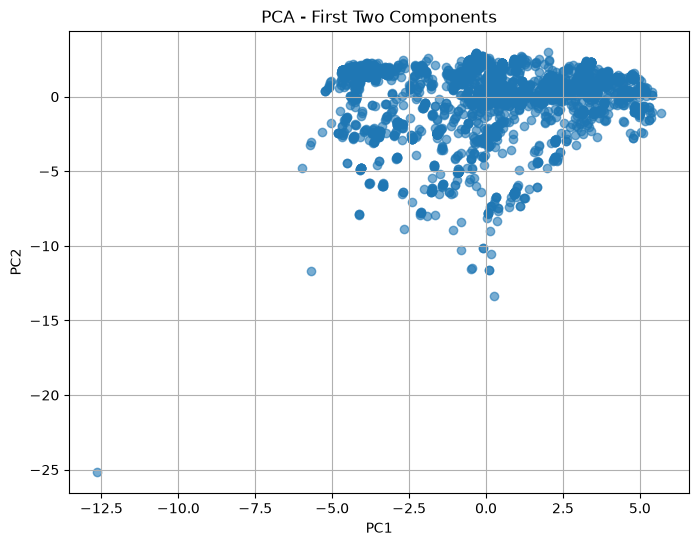

In [17]:
plt.figure(figsize=(8,6))
plt.scatter(pca_df["PC1"], pca_df["PC2"], alpha=0.6)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - First Two Components")
plt.grid(True)
plt.show()


In [18]:
# Compute Spearman rank correlation
spearman_corr_matrix = merged_csv[selected_cols].corr(method='spearman')

# View the strongest correlations
strong_spearman = spearman_corr_matrix[(spearman_corr_matrix.abs() > 0.7) & (spearman_corr_matrix.abs() < 1.0)]


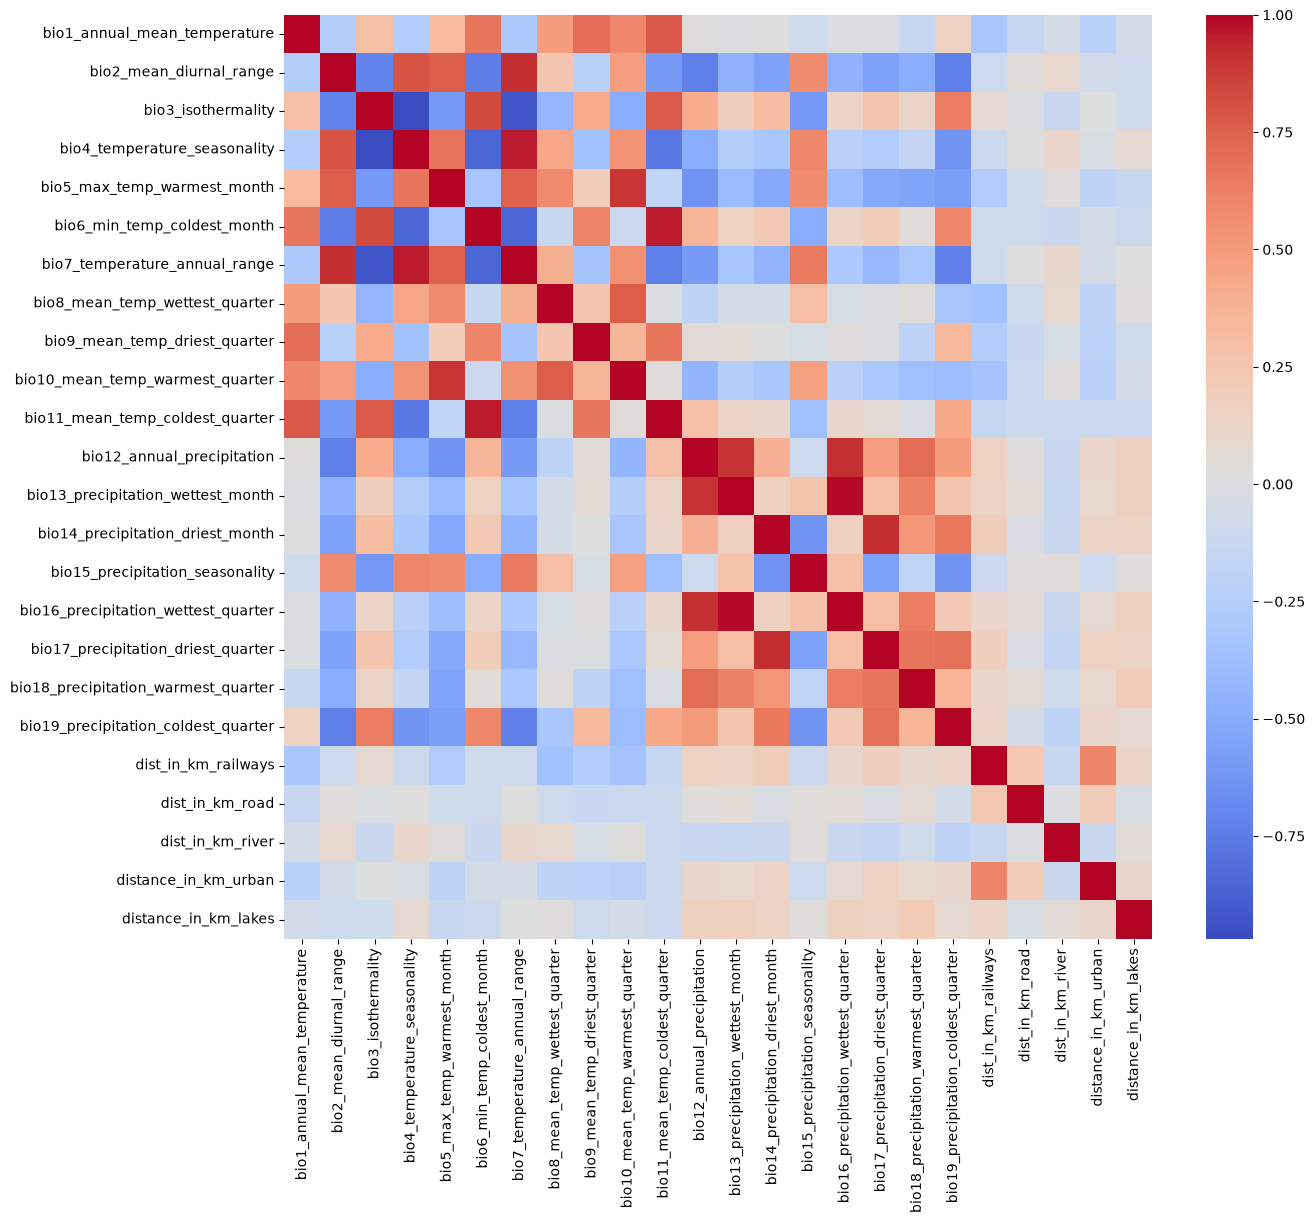

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14,12))
sns.heatmap(spearman_corr_matrix, cmap="coolwarm", annot=False)
plt.show()


In [21]:
# Add constant for intercept
X_const = sm.add_constant(pca_df)
logit_model = sm.Logit(y, X_const).fit()

# View coefficients, p-values, and Odds Ratios
summary_df = pd.DataFrame({
    'Coefficient (Beta)': logit_model.params,
    'Odds Ratio': np.exp(logit_model.params),
    'p-value': logit_model.pvalues
})
print(summary_df)

         Current function value: 0.000000
         Iterations: 35
       Coefficient (Beta)    Odds Ratio   p-value
const        2.551139e+01  1.200757e+11  0.996536
PC1          3.159611e-16  1.000000e+00  1.000000
PC2         -1.203227e-16  1.000000e+00  1.000000
PC3          4.558105e-16  1.000000e+00  1.000000
PC4          3.645113e-17  1.000000e+00  1.000000
PC5          4.485518e-16  1.000000e+00  1.000000
PC6          8.497939e-16  1.000000e+00  1.000000


C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
C:\Users\hibah\anaconda3\envs\spatial_env\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect

In [22]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(pca_df, y)

importance_df = pd.DataFrame({
    'Factor': pca_df.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)
print(importance_df)

  Factor  Importance
0    PC1         0.0
1    PC2         0.0
2    PC3         0.0
3    PC4         0.0
4    PC5         0.0
5    PC6         0.0


In [23]:
# Check what is actually inside your occurrence column
print(merged_csv['occurrenceStatus'].value_counts(dropna=False))

# Check the generated target array
print("Unique values in y:", set(y))

occurrenceStatus
PRESENT    3477
Name: count, dtype: int64
Unique values in y: {1}


In [24]:
summary_df

,Coefficient (Beta),Odds Ratio,p-value
const,2.551139e+01,1.200757e+11,0.996536
PC1,3.159611e-16,1.000000e+00,1.000000
PC2,-1.203227e-16,1.000000e+00,1.000000
PC3,4.558105e-16,1.000000e+00,1.000000
PC4,3.645113e-17,1.000000e+00,1.000000
PC5,4.485518e-16,1.000000e+00,1.000000
PC6,8.497939e-16,1.000000e+00,1.000000


In [25]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load datasets
absence = pd.read_csv("India_Lantana_Absences_Generated.csv")
presence = pd.read_csv("India_Lantana_Complete_Model_Inputs.csv")

# Create target for presence data
presence["target"] = 1

# Keep only common columns
common_cols = list(set(absence.columns) & set(presence.columns))

absence = absence[common_cols]
presence = presence[common_cols]

# Combine datasets
df = pd.concat([presence, absence], ignore_index=True)

# Features and target
X = df.drop(columns=["target", "occurrenceStatus"], errors="ignore")
y = df["target"]

# Handle missing values
X = X.fillna(X.median(numeric_only=True))

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic Regression
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

# Predictions
y_pred = model.predict(X_test_scaled)

y_pred_train = model.predict(X_train_scaled)
print("Accuracy train:", accuracy_score(y_train, y_pred_train))
# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Accuracy train: 0.9982024087722452
Accuracy: 0.9985621854780733

Confusion Matrix
[[694   2]
 [  0 695]]

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       696
           1       1.00      1.00      1.00       695

    accuracy                           1.00      1391
   macro avg       1.00      1.00      1.00      1391
weighted avg       1.00      1.00      1.00      1391



In [26]:
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()

print(
    coef_df.sort_values(
        "Abs_Coefficient",
        ascending=False
    ).head(10)
)


                Feature  Coefficient  Abs_Coefficient
0      dist_in_km_river    -3.104942         3.104942
1  distance_in_km_urban    -2.782166         2.782166
2       dist_in_km_road    -2.776037         2.776037
3   dist_in_km_railways    -2.186680         2.186680
4  distance_in_km_lakes    -2.104668         2.104668


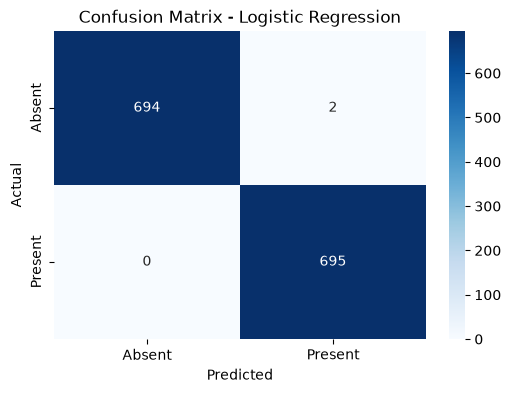

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=['Absent','Present'],
            yticklabels=['Absent','Present'])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

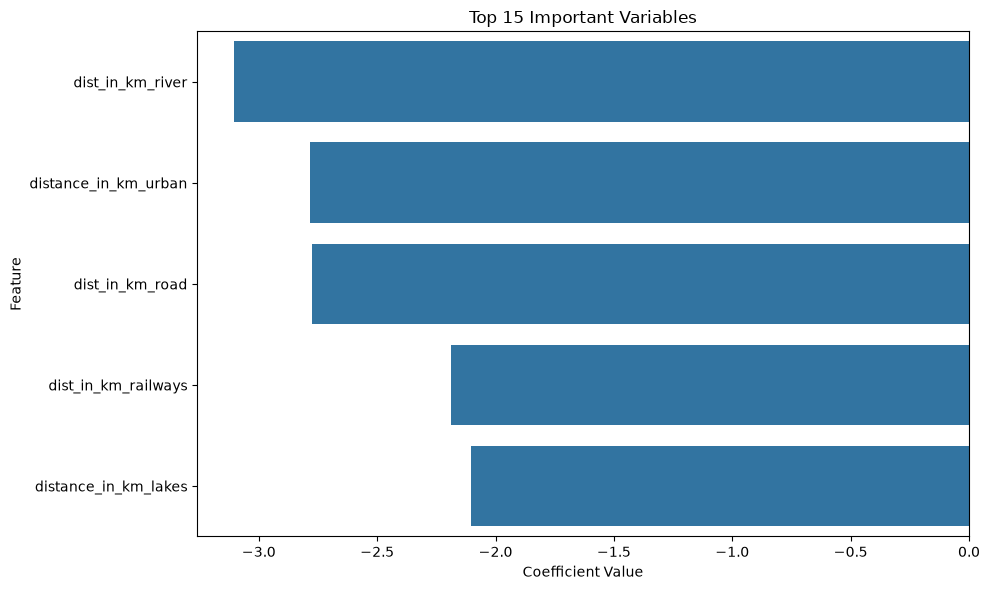

In [28]:
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

coef_df = coef_df.sort_values(
    by='Coefficient',
    key=abs,
    ascending=False
)

plt.figure(figsize=(10,6))
sns.barplot(
    data=coef_df.head(15),
    x='Coefficient',
    y='Feature'
)

plt.title('Top 15 Important Variables')
plt.xlabel('Coefficient Value')
plt.tight_layout()
plt.show()

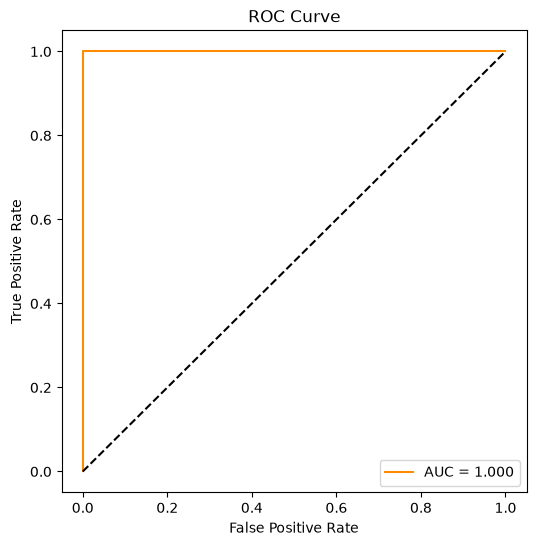

In [29]:
from sklearn.metrics import roc_curve, auc

y_prob = model.predict_proba(X_test_scaled)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr,
         label=f'AUC = {roc_auc:.3f}',
         color='darkorange')

plt.plot([0,1],[0,1],'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

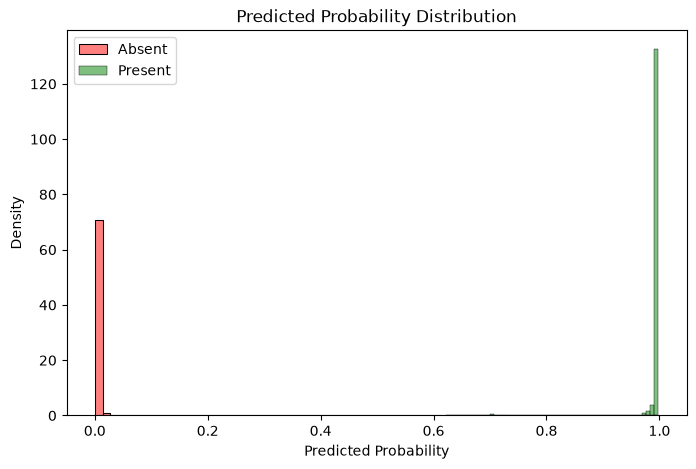

In [30]:
plt.figure(figsize=(8,5))

sns.histplot(
    y_prob[y_test==0],
    color='red',
    label='Absent',
    stat='density',
    alpha=0.5
)

sns.histplot(
    y_prob[y_test==1],
    color='green',
    label='Present',
    stat='density',
    alpha=0.5
)

plt.xlabel("Predicted Probability")
plt.title("Predicted Probability Distribution")
plt.legend()
plt.show()

In [31]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load datasets
absence = pd.read_csv("India_Lantana_Absences_Generated.csv")
presence = pd.read_csv("India_Lantana_Complete_Model_Inputs.csv")

# Create target for presence data
presence["target"] = 1

# Keep only common columns
common_cols = list(set(absence.columns) & set(presence.columns))

absence = absence[common_cols]
presence = presence[common_cols]

# Combine datasets
df = pd.concat([presence, absence], ignore_index=True)

# Features and target
X = df.drop(columns=["target", "occurrenceStatus"], errors="ignore")
y = df["target"]

# Handle missing values
X = X.fillna(X.median(numeric_only=True))

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic Regression
model = DecisionTreeClassifier(max_depth=1000)

model.fit(X_train_scaled, y_train)
#test
y_pred_train = model.predict(X_train_scaled)
print("Accuracy train:", accuracy_score(y_train, y_pred_train))
# Evaluation
# Predictions
y_pred = model.predict(X_test_scaled)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Accuracy train: 1.0
Accuracy: 0.9964054636951833

Confusion Matrix
[[695   1]
 [  4 691]]

Classification Report
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       696
           1       1.00      0.99      1.00       695

    accuracy                           1.00      1391
   macro avg       1.00      1.00      1.00      1391
weighted avg       1.00      1.00      1.00      1391



In [32]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load datasets
absence = pd.read_csv("India_Lantana_Absences_Generated.csv")
presence = pd.read_csv("India_Lantana_Complete_Model_Inputs.csv")

# Create target for presence data
presence["target"] = 1

# Keep only common columns
common_cols = list(set(absence.columns) & set(presence.columns))

absence = absence[common_cols]
presence = presence[common_cols]

# Combine datasets
df = pd.concat([presence, absence], ignore_index=True)

# Features and target
X = df.drop(columns=["target", "occurrenceStatus"], errors="ignore")
y = df["target"]

# Handle missing values
X = X.fillna(X.median(numeric_only=True))

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic Regression
model = RandomForestClassifier(max_depth=1000)

model.fit(X_train_scaled, y_train)

y_pred_train = model.predict(X_train_scaled)
print("Accuracy train:", accuracy_score(y_train, y_pred_train))
# Evaluation
# Predictions
y_pred = model.predict(X_test_scaled)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Accuracy train: 1.0
Accuracy: 0.9978432782171099

Confusion Matrix
[[696   0]
 [  3 692]]

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       696
           1       1.00      1.00      1.00       695

    accuracy                           1.00      1391
   macro avg       1.00      1.00      1.00      1391
weighted avg       1.00      1.00      1.00      1391



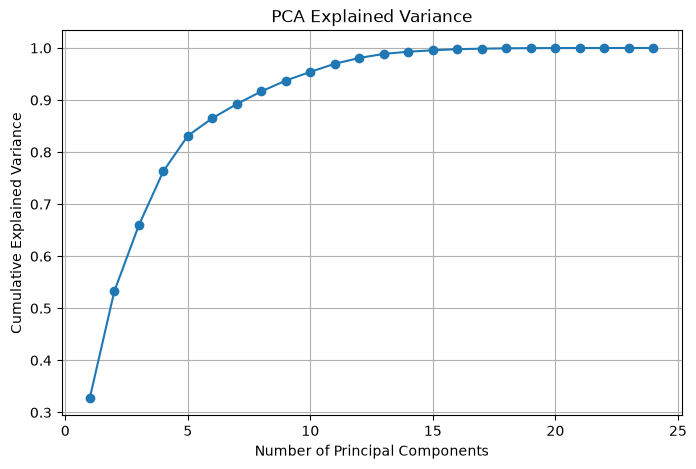

In [33]:
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained_var = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8,5))
plt.plot(range(1, len(explained_var)+1), explained_var, marker='o')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid(True)
plt.show()

In [34]:
pca = PCA(n_components=0.95)

X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X.shape)
print("New Shape:", X_pca.shape)


Original Shape: (6954, 5)
New Shape: (3477, 10)


In [35]:
pca = PCA(n_components=10)
X_pca = pca.fit_transform(X_scaled)

In [40]:
import numpy as np
import pandas as pd
from astropy.stats import jackknife_resampling, jackknife_stats

In [41]:
import numpy as np

n = len(df)

jackknife_samples = [
    df.drop(df.index[i])
    for i in range(n)
]

In [43]:
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [44]:
df_new = df.drop(columns = ["occurrenceStatus","target"])
X = add_constant(df_new)

vif = pd.DataFrame()
vif["Feature"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i)
              for i in range(X.shape[1])]

print(vif)

                Feature       VIF
0                 const  1.000000
1      dist_in_km_river  2.013821
2  distance_in_km_urban  1.959469
3       dist_in_km_road  1.987954
4   dist_in_km_railways  2.022843
5  distance_in_km_lakes  1.920789


Number of occurrence points: 3477
Raster CRS: EPSG:4326


C:\Users\hibah\AppData\Local\Temp\ipykernel_30556\2075579331.py:69: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  kg_data = src.read(1, window=window)


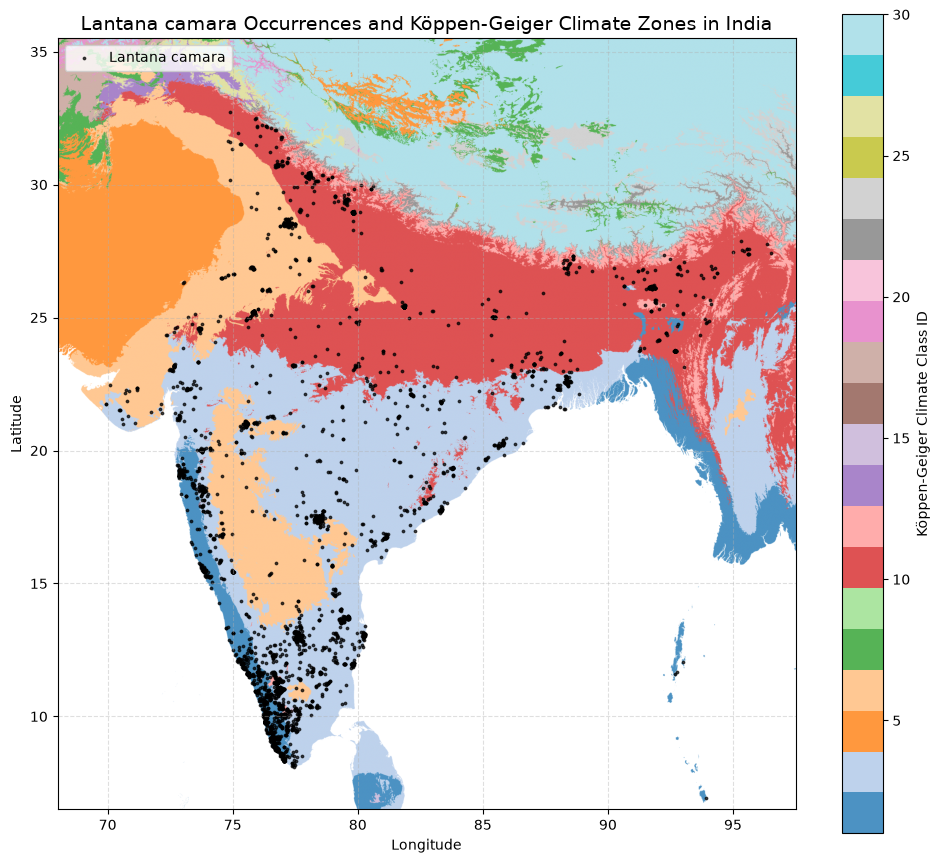

In [45]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.windows import from_bounds
from rasterio.windows import transform as window_transform
from rasterio.transform import array_bounds
from matplotlib.colors import ListedColormap


csv_file = r"rd/Lantana_camara_India.csv"

df = pd.read_csv(csv_file)

# Remove records with missing coordinates
df = df.dropna(subset=["decimalLongitude", "decimalLatitude"])

# Keep only points within India's approximate extent
df = df[
    (df["decimalLongitude"] >= 68.0)
    & (df["decimalLongitude"] <= 98.0)
    & (df["decimalLatitude"] >= 6.0)
    & (df["decimalLatitude"] <= 38.0)
]

# Convert to GeoDataFrame
gdf_points = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df.decimalLongitude, df.decimalLatitude),
    crs="EPSG:4326",
)

print(f"Number of occurrence points: {len(gdf_points)}")


tif_path = r"C:/Users/hibah/rd/koppen_geiger_0p00833333.tif"

india_bbox = (
    68.0,   # min longitude
    6.5,    # min latitude
    97.5,   # max longitude
    35.5    # max latitude
)

with rasterio.open(tif_path) as src:

    print("Raster CRS:", src.crs)

    # Reproject occurrence points if raster CRS differs
    if gdf_points.crs != src.crs:
        gdf_points = gdf_points.to_crs(src.crs)

    window = from_bounds(
        *india_bbox,
        transform=src.transform
    )

    kg_data = src.read(1, window=window)

    kg_transform = window_transform(
        window,
        src.transform
    )

# Convert ocean/no-data values to NaN
kg_data = np.where(kg_data == 0, np.nan, kg_data)

height, width = kg_data.shape

west, south, east, north = array_bounds(
    height,
    width,
    kg_transform
)

extent = [west, east, south, north]

try:
    world = gpd.read_file(
        gpd.datasets.get_path("naturalearth_lowres")
    )

    india = world[world["name"] == "India"]

except Exception:
    india = None

fig, ax = plt.subplots(figsize=(10, 12))

# Categorical color map
cmap = plt.cm.tab20

img = ax.imshow(
    kg_data,
    extent=extent,
    cmap=cmap,
    origin="upper",
    alpha=0.8,
)

# India boundary
if india is not None:
    india.boundary.plot(
        ax=ax,
        color="black",
        linewidth=1.0
    )

# Occurrence points
gdf_points.plot(
    ax=ax,
    color="black",
    markersize=3,
    alpha=0.7,
    label="Lantana camara"
)

# Colorbar
cbar = plt.colorbar(
    img,
    ax=ax,
    shrink=0.7
)

cbar.set_label("Köppen-Geiger Climate Class ID")

# Labels
ax.set_title(
    "Lantana camara Occurrences and Köppen-Geiger Climate Zones in India",
    fontsize=14,
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.legend(loc="upper left")

ax.grid(
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

In [46]:
with rasterio.open(tif_path) as src:
    # Sample raster pixel values at point coordinates
    coord_pairs = zip(gdf_points.geometry.x, gdf_points.geometry.y)
    gdf_points["koppen_class"] = [x[0] for x in src.sample(coord_pairs)]

# Map numeric IDs to climate labels from legend.txt if needed
print(gdf_points[["decimalLatitude", "decimalLongitude", "koppen_class"]].head())

   decimalLatitude  decimalLongitude  koppen_class
0         6.950555         93.919205             1
1        11.594292         76.069466             2
2        11.596206         76.176885             2
3        11.596447         75.823326             2
4        11.601290         76.177000             2


In [47]:
import numpy as np

# Target IDs for Af, Am, Aw, and BSh from legend.txt
target_ids = [1, 2, 3, 6]

# Create a boolean mask (True for blue and orange climate pixels)
target_mask = np.isin(kg_data, target_ids)

# Keep only target climate values, mask everything else as NaN
filtered_kg_data = np.where(target_mask, kg_data, np.nan)

In [48]:
# Target climate IDs
target_ids = [1, 2, 3, 6]

# Keep only points in selected climates
lantana_selected = gdf_points[
    gdf_points["koppen_class"].isin(target_ids)
].copy()

print(f"Occurrences in selected climates: {len(lantana_selected)}")

# View coordinates
print(
    lantana_selected[
        ["decimalLatitude", "decimalLongitude", "koppen_class"]
    ].head()
)


Occurrences in selected climates: 2819
   decimalLatitude  decimalLongitude  koppen_class
0         6.950555         93.919205             1
1        11.594292         76.069466             2
2        11.596206         76.176885             2
3        11.596447         75.823326             2
4        11.601290         76.177000             2


In [49]:
print(gdf_points.columns)

Index(['gbifID', 'decimalLongitude', 'decimalLatitude', 'dist_in_km_railways',
       'dist_in_km_road', 'distance_in_km_urban', 'distance_in_km_lakes',
       'dist_in_km_river', 'bio1_annual_mean_temperature',
       'bio10_mean_temp_warmest_quarter', 'bio11_mean_temp_coldest_quarter',
       'bio12_annual_precipitation', 'bio13_precipitation_wettest_month',
       'bio14_precipitation_driest_month', 'bio15_precipitation_seasonality',
       'bio16_precipitation_wettest_quarter',
       'bio17_precipitation_driest_quarter',
       'bio18_precipitation_warmest_quarter',
       'bio19_precipitation_coldest_quarter', 'bio2_mean_diurnal_range',
       'bio3_isothermality', 'bio4_temperature_seasonality',
       'bio5_max_temp_warmest_month', 'bio6_min_temp_coldest_month',
       'bio7_temperature_annual_range', 'bio8_mean_temp_wettest_quarter',
       'bio9_mean_temp_driest_quarter', 'geometry', 'koppen_class'],
      dtype='str')


In [50]:
with rasterio.open(tif_path) as src:

    # Reproject points if necessary
    if gdf_points.crs != src.crs:
        gdf_points = gdf_points.to_crs(src.crs)

    coords = [
        (geom.x, geom.y)
        for geom in gdf_points.geometry
    ]

    gdf_points["koppen_class"] = [
        val[0]
        for val in src.sample(coords)
    ]

In [51]:
target_ids = [1, 2, 3, 6]

lantana_selected = gdf_points[
    gdf_points["koppen_class"].isin(target_ids)
].copy()

print(f"Selected records: {len(lantana_selected)}")

Selected records: 2819


In [52]:
output = lantana_selected[
    [
        "decimalLatitude",
        "decimalLongitude",
        "koppen_class"
    ]
]

output.to_csv(
    r"C:\Users\hibah\rd\Lantana_Selected_Koppen.csv",
    index=False
)

print(output.head())

   decimalLatitude  decimalLongitude  koppen_class
0         6.950555         93.919205             1
1        11.594292         76.069466             2
2        11.596206         76.176885             2
3        11.596447         75.823326             2
4        11.601290         76.177000             2


In [56]:
import rasterio
import numpy as np

# Coordinates from Lantana points
coords = [(geom.x, geom.y) for geom in gdf_points.geometry]

# Extract raster values at occurrence locations
with rasterio.open(tif_path) as src:
    values = [x[0] for x in src.sample(coords)]

# Remove NoData values
values = np.array(values)
values = values[values != src.nodata]

# Unique Köppen IDs
unique_koppen_ids = np.unique(values)

print("Unique Köppen IDs occupied by Lantana:")
print(unique_koppen_ids)

Unique Köppen IDs occupied by Lantana:
[ 1  2  3  6 11 12 15]
